In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn import metrics
%matplotlib

Using matplotlib backend: module://matplotlib_inline.backend_inline


In [13]:
bit = pd.read_csv('bitcoin_updated.csv')

In [14]:
bit.head(-5)

,Date,Open,High,Low,Close,Vol.
0,2013-01-01,13.500000,13.600000,13.200000,13.300000,28.41K
1,2013-01-02,13.300000,13.400000,13.200000,13.300000,17.97K
2,2013-01-03,13.300000,13.500000,13.300000,13.400000,18.03K
3,2013-01-04,13.400000,13.500000,13.300000,13.500000,29.64K
4,2013-01-05,13.500000,13.600000,13.300000,13.400000,21.33K
...,...,...,...,...,...,...
5042,2026-10-22,84011.968750,84301.281250,80841.273438,81311.890625,33451533824
5043,2026-10-23,81311.890625,81956.343750,80421.742188,81074.187500,23489312165
5044,2026-10-24,81074.187500,81098.242188,79145.539062,80790.835938,21271255914
5045,2026-10-25,80790.835938,80928.265625,79766.828125,80024.007812,12096386141


In [15]:
bit.info()

<class 'pandas.DataFrame'>
RangeIndex: 5052 entries, 0 to 5051
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    5052 non-null   str    
 1   Open    5052 non-null   float64
 2   High    5052 non-null   float64
 3   Low     5052 non-null   float64
 4   Close   5052 non-null   float64
 5   Vol.    5052 non-null   str    
dtypes: float64(4), str(2)
memory usage: 236.9 KB


In [16]:
bit.describe()

,Open,High,Low,Close
count,5052.000000,5052.000000,5052.000000,5052.000000
mean,26390.678805,26915.072271,25832.805737,26406.073742
std,32290.248319,32829.219011,31716.187343,32296.190903
min,13.300000,13.400000,13.200000,13.300000
25%,649.950000,662.500000,631.350000,650.300000
50%,9473.150000,9688.500000,9250.250000,9483.650000
75%,44001.898438,44838.625000,42936.206445,44001.676758
max,124752.140625,126198.070312,123196.046875,124752.531250


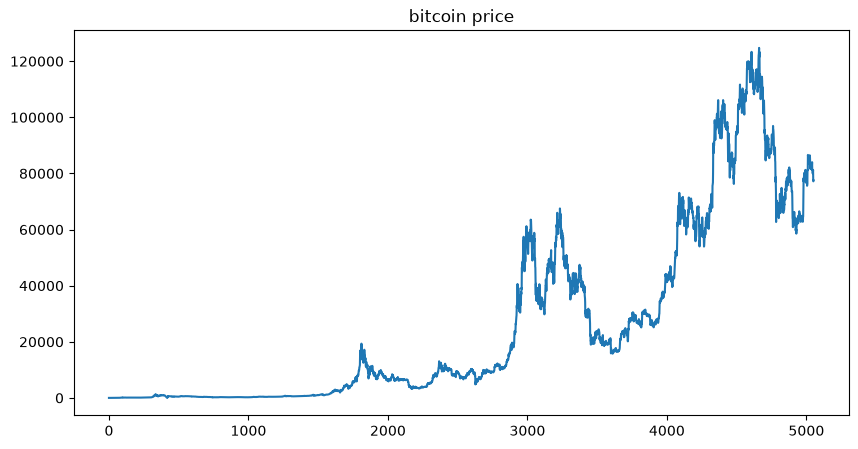

In [17]:
plt.figure(figsize=(10,5))
plt.plot(bit['Close'])
plt.title('bitcoin price')
plt.show()

In [18]:
bit.isnull().sum()

Date     0
Open     0
High     0
Low      0
Close    0
Vol.     0
dtype: int64

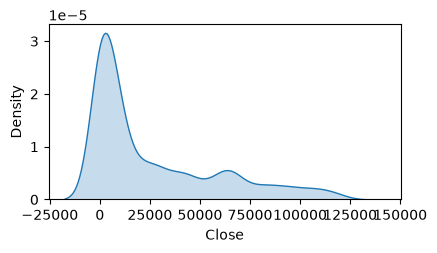

In [19]:
plt.close()
plt.figure(figsize=(10,5))

plt.subplot(2,2,1)
sb.kdeplot(bit['Close'], fill=True)

plt.show()

In [20]:
splitted = bit['Date'].str.split('-', expand=True)

In [21]:
bit['year'] = splitted[0].astype('int')
bit['month'] = splitted[1].astype('int')
bit['day'] = splitted[2].astype('int')

In [22]:
bit.head()

,Date,Open,High,Low,Close,Vol.,year,month,day
0,2013-01-01,13.5,13.6,13.2,13.3,28.41K,2013,1,1
1,2013-01-02,13.3,13.4,13.2,13.3,17.97K,2013,1,2
2,2013-01-03,13.3,13.5,13.3,13.4,18.03K,2013,1,3
3,2013-01-04,13.4,13.5,13.3,13.5,29.64K,2013,1,4
4,2013-01-05,13.5,13.6,13.3,13.4,21.33K,2013,1,5


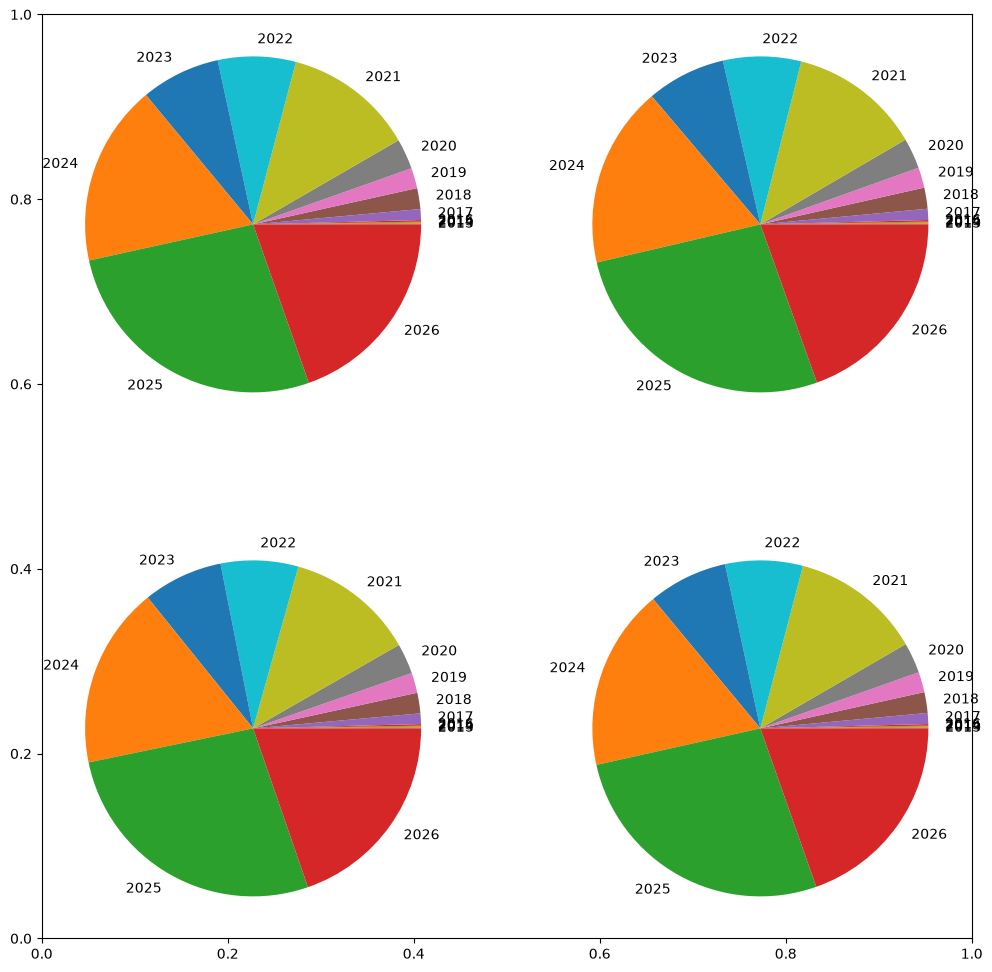

In [23]:
plt.close()
data_grouped = bit.groupby('year').mean(numeric_only=True)
plt.subplots(figsize=(12,12))
for i, col in enumerate(['Open', 'High', 'Low', 'Close']):
    plt.subplot(2,2,1+i)
    data_grouped[col].plot.pie()
plt.show()

In [24]:
bit['is_quarter_end'] = np.where(bit['month']%3 ==0,1,0)
bit.head()

,Date,Open,High,Low,Close,Vol.,year,month,day,is_quarter_end
0,2013-01-01,13.5,13.6,13.2,13.3,28.41K,2013,1,1,0
1,2013-01-02,13.3,13.4,13.2,13.3,17.97K,2013,1,2,0
2,2013-01-03,13.3,13.5,13.3,13.4,18.03K,2013,1,3,0
3,2013-01-04,13.4,13.5,13.3,13.5,29.64K,2013,1,4,0
4,2013-01-05,13.5,13.6,13.3,13.4,21.33K,2013,1,5,0


In [26]:
bit['open-close'] = bit['Open'] - bit['Close']
bit['low-high'] = bit['Low'] - bit['High']
#bit = bit.drop('close-open', axis='columns')
bit.head()

,Date,Open,High,Low,Close,Vol.,year,month,day,is_quarter_end,open-close,low-high
0,2013-01-01,13.5,13.6,13.2,13.3,28.41K,2013,1,1,0,0.2,-0.4
1,2013-01-02,13.3,13.4,13.2,13.3,17.97K,2013,1,2,0,0.0,-0.2
2,2013-01-03,13.3,13.5,13.3,13.4,18.03K,2013,1,3,0,-0.1,-0.2
3,2013-01-04,13.4,13.5,13.3,13.5,29.64K,2013,1,4,0,-0.1,-0.2
4,2013-01-05,13.5,13.6,13.3,13.4,21.33K,2013,1,5,0,0.1,-0.3


In [27]:
bit['target'] = np.where(bit['Close'].shift(-1) > bit['Close'] , 1 , 0) #shift -1 ==> next

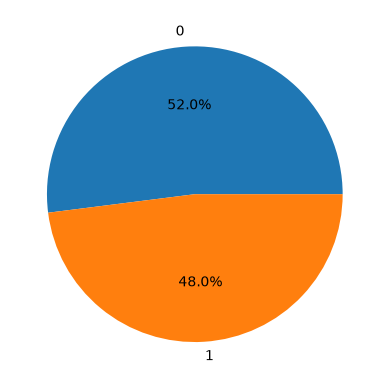

In [28]:
plt.close()
plt.pie(bit['target'].value_counts().values,labels=[0,1], autopct='%1.1f%%')
plt.show()

In [29]:
features = bit[['open-close', 'low-high', 'is_quarter_end']]
target = bit['target']

scaler = StandardScaler()
features = scaler.fit_transform(features)

X_train, X_valid, y_train, y_valid = train_test_split(features, target, test_size=0.15)

In [30]:
model = LogisticRegression()
model.max_iter=10000
model.fit(X_train,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 

In [ ]:
out = model.predict(X_valid)
out

array([1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0,
       0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,

In [ ]:
y_valid

4218    1
2465    0
3746    0
5020    1
105     1
       ..
700     0
915     0
1998    1
922     0
1188    1
Name: target, Length: 758, dtype: int64

In [31]:
models = [LogisticRegression(), DecisionTreeClassifier(), KNeighborsClassifier()]

for i in range(3):
    models[i].max_iter=10000
    models[i].fit(X_train,y_train)

    print(f'{models[i]} :')
    print('training accuarcy :' , metrics.roc_auc_score(y_train, models[i].predict_proba(X_train)[:,1]))
    print('validation accuarcy :' , metrics.roc_auc_score(y_valid, models[i].predict_proba(X_valid)[:,1]))
    print()

LogisticRegression(max_iter=10000) :
training accuarcy : 0.5335672337946863
validation accuarcy : 0.5113806528900868

DecisionTreeClassifier() :
training accuarcy : 0.9999946750243428
validation accuarcy : 0.5063763694742194

KNeighborsClassifier() :
training accuarcy : 0.7465383311308944
validation accuarcy : 0.47617306393085246

